# CV story, part 1: model selection (Stages A-C)

Recomputes every number and figure of the deck slides on data, protocol, Stages A-C and the final config choice, straight from the run outputs. Nothing is retrained.

Inputs: `cache/preds/<tag>.npz` (one per run: val + test windows of its fold, `truth`, `pred`), `cache/runs/*.json`, `cache/results/summary.csv` (`scripts/aggregate_runs.py`), `cache/windows/`, `cache/folds.json`.
Outputs: figures `cache/deck/cv_story/*.png` and the cited numbers `cache/deck/cv_story/values.json` (the deck generator reads both; part 2 `cv_gate_smoothing.ipynb` adds its own keys).

Selection logic is the library's (`bpm.aggregate.decide`), not re-implemented here.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

from bpm.aggregate import BIN_EDGES, decide, ltgo_folds, macro, parse_tag, subject_mae

PREDS = ROOT / "cache" / "preds"
RESULTS = ROOT / "cache" / "results"
OUT = ROOT / "cache" / "deck" / "cv_story"   # figures + values.json for the deck
OUT.mkdir(parents=True, exist_ok=True)
DATASETS = ["multisite-ppg", "wrist-finger-ppg"]

## Style

Single source of truth for every plot below. Colors come from a colorblind-safe palette and are bound to **roles**: a config keeps its color in every figure of both notebooks. Plot cells never use a raw hex color or font size.

In [2]:
# palette of docs/hr_cnn_bilstm_results.odp (the deck these figures get merged into):
# ink #212a30, accent green #1e7f5c, red #b03a2e, secondary #555b60, muted #7a7f84, light #c9d1cd, card #edf2f0
COLORS = {
    # configs (role = model family): baselines slate/grey, MSE + boot red, dist + boot green
    "mse": "#212a30", "huber10": "#555b60", "mae": "#7a7f84",
    "mse_bootHL": "#b03a2e", "mse_bootHL_lds0.5": "#b03a2e", "mse_bootHL_lds1": "#b03a2e",
    "dist_bootHL": "#1e7f5c", "dist_bootHL_lds0.5": "#1e7f5c", "dist_bootHL_lds1": "#1e7f5c",
    # datasets
    "multisite-ppg": "#212a30", "wrist-finger-ppg": "#1e7f5c",
    # scores (line style separates the greys, see SCORE_LS)
    "score_std": "#1e7f5c", "score_mc": "#b03a2e", "score_spread": "#212a30",
    "prominence": "#7a7f84", "skew": "#7a7f84",
    # smoothers
    "raw": "#7a7f84", "median": "#555b60", "kalman": "#1e7f5c", "hmm": "#212a30",
    # signals
    "truth": "#212a30", "ideal": "#7a7f84", "bad": "#b03a2e", "good": "#1e7f5c", "neutral": "#c9d1cd",
    # ink and surface
    "text": "#212a30", "muted": "#7a7f84", "grid": "#e8ecea", "surface": "#ffffff",
}
SCORE_LS = {"score_std": "-", "score_mc": "-", "score_spread": "-", "prominence": "-", "skew": "--"}
# LDS power shown by marker (scatter) / line style (curves), so 3 hues cover all 9 configs
MARKERS = {"": "o", "lds0.5": "s", "lds1": "^"}
LINESTYLES = {"": "-", "lds0.5": "--", "lds1": ":"}
LABELS = {
    "mse": "MSE", "huber10": "Huber δ10", "mae": "MAE",
    "mse_bootHL": "MSE + boot", "mse_bootHL_lds0.5": "MSE + boot + LDS 0.5", "mse_bootHL_lds1": "MSE + boot + LDS 1",
    "dist_bootHL": "dist + boot", "dist_bootHL_lds0.5": "dist + boot + LDS 0.5", "dist_bootHL_lds1": "dist + boot + LDS 1",
}
STYLE = {"fig_w": 10, "row_h": 4.2, "dpi": 110, "save_dpi": 200, "font": 11, "title": 13,
         "lw": 1.8, "lw_thin": 1.0, "marker": 70, "alpha": 0.25}

plt.rcParams.update({
    "figure.dpi": STYLE["dpi"], "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "figure.constrained_layout.use": True,
    "font.size": STYLE["font"], "axes.titlesize": STYLE["title"], "axes.labelsize": STYLE["font"],
    "legend.fontsize": STYLE["font"] - 1, "legend.frameon": False,
    "text.color": COLORS["text"], "axes.labelcolor": COLORS["text"], "axes.edgecolor": COLORS["muted"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": STYLE["lw"],
    "font.family": "Lato",  # the deck's body font as rendered here (Calibri falls back to it)
})
from matplotlib.colors import LinearSegmentedColormap
DENSITY_CMAP = LinearSegmentedColormap.from_list("deck", ["#edf2f0", "#1e7f5c", "#212a30"])


def figsize(rows=1, w=None):
    return (w or STYLE["fig_w"], STYLE["row_h"] * rows)


def lds_of(cfg):
    return next((p for p in ("lds0.5", "lds1") if cfg.endswith(p)), "")


def save(fig, name):
    """Figure for the deck: cache/deck/cv_story/<name>.png."""
    fig.savefig(OUT / f"{name}.png", dpi=STYLE["save_dpi"], facecolor=COLORS["surface"])


VALUES_PATH = OUT / "values.json"
VALUES = json.loads(VALUES_PATH.read_text()) if VALUES_PATH.exists() else {}


def put(section, **kv):
    """Record numbers the deck cites (values.json, merged across both notebooks)."""
    conv = lambda v: v.item() if hasattr(v, "item") else v
    VALUES.setdefault(section, {}).update({k: conv(v) for k, v in kv.items()})
    VALUES_PATH.write_text(json.dumps(VALUES, indent=1, default=float))


BIN_LABELS = [f"{lo}-{hi}" if np.isfinite(hi) else f"{lo}+" for lo, hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:])]


def bin_of(truth):
    return pd.cut(truth, BIN_EDGES, right=False, labels=BIN_LABELS)

## Load all single-seed runs

One row per (run, window): 9 configs x 5 folds x 3 seeds, val and test windows of each run's fold. `err = |pred - truth|`.

In [3]:
STAGES = {
    "A": ["huber10", "mae", "mse"],
    "B": ["mse_bootHL", "mse_bootHL_lds0.5", "mse_bootHL_lds1"],
    "C": ["dist_bootHL", "dist_bootHL_lds0.5", "dist_bootHL_lds1"],
}
CONFIGS = [c for s in STAGES.values() for c in s]

parts = []
for p in sorted(PREDS.glob("*.npz")):
    parsed = parse_tag(p.stem)
    if parsed is None or parsed[2] is None:  # skip ensembles (part 2)
        continue
    z = np.load(p)
    parts.append(pd.DataFrame({"config": parsed[0], "fold": parsed[1], "seed": parsed[2], "split": z["split"],
                               "dataset": z["dataset_source"], "subject": z["subject"],
                               "truth": z["truth"].astype(float), "pred": z["pred"].astype(float)}))
W = pd.concat(parts, ignore_index=True)
W["err"] = (W["pred"] - W["truth"]).abs()
W["bin"] = bin_of(W["truth"])
runs = pd.DataFrame([json.loads(p.read_text()) for p in sorted((ROOT / "cache" / "runs").glob("*.json"))])
runs["config"] = runs["tag"].map(lambda t: parse_tag(t)[0])

assert set(W["config"]) == set(CONFIGS), set(W["config"]) ^ set(CONFIGS)
check = W.groupby("config")[["fold", "seed"]].apply(lambda g: len(g.drop_duplicates()))
assert (check == 15).all(), check
assert (runs["rc"] == 0).all() and (runs["eval_rc"] == 0).all()
print(f"{len(W):,} window rows, {W.groupby(['config', 'fold', 'seed']).ngroups} runs")
runs.groupby("config")[["best_epoch", "stop_epoch", "collapsed"]].agg(["mean", "min", "max"]).round(1)

2,800,656 window rows, 135 runs


best_epoch         stop_epoch         collapsed         \
                         mean min max       mean min max      mean    min   
config                                                                      
dist_bootHL              19.3   6  37       39.3  26  57       0.0  False   
dist_bootHL_lds0.5       17.1  11  29       37.1  31  49       0.0  False   
dist_bootHL_lds1         29.5  10  81       49.3  30  99       0.0  False   
huber10                  20.3   4  47       40.3  24  67       0.0  False   
mae                      20.6   4  34       40.6  24  54       0.0  False   
mse                      26.3  13  67       46.3  33  87       0.0  False   
mse_bootHL               31.4  12  58       51.4  32  78       0.0  False   
mse_bootHL_lds0.5        16.7   3  34       36.7  23  54       0.0  False   
mse_bootHL_lds1          20.3   3  39       40.3  23  59       0.0  False   

                           
                      max  
config                     
dist_bootHL         False  
dist_bootHL_lds0.5  False  
dist_bootHL_lds1    False  
huber10             False  
mae                 False  
mse                 False  
mse_bootHL          False  
mse_bootHL_lds0.5   False  
mse_bootHL_lds1     False

## 1. Data

Windows and subjects per sub-dataset as cached (`cache/windows/`, up to 2000 windows per subject), and the BPM label distribution. The label distribution is the root of "the problem" further down: most windows sit at 60-90 BPM, the high bins are thin.

In [4]:
folds = json.loads((ROOT / "cache" / "folds.json").read_text())
rows = []
for p in sorted((ROOT / "cache" / "windows").glob("*.npz")):
    z = np.load(p)
    rows.append(pd.DataFrame({"subject": p.stem, "dataset": z["dataset_source"], "truth": z["labels"].astype(float)}))
L = pd.concat(rows, ignore_index=True)
L["dataset"] = L["dataset"].replace({"multisite": "multisite-ppg", "wrist-finger": "wrist-finger-ppg"})
L["group"] = L["subject"].map(lambda s: folds[s]["group"])
L["bin"] = bin_of(L["truth"])

overview = L.groupby("dataset").agg(subjects=("subject", "nunique"), windows=("truth", "size"),
                                    bpm_mean=("truth", "mean"), bpm_sd=("truth", "std"),
                                    bpm_min=("truth", "min"), bpm_max=("truth", "max")).round(1)
share = pd.crosstab(L["bin"], L["dataset"], normalize="columns").mul(100).round(1)
put("data", subjects=int(overview["subjects"].sum()), windows=int(overview["windows"].sum()),
    **{f"subjects_{d}": int(overview.loc[d, "subjects"]) for d in overview.index},
    **{f"windows_{d}": int(overview.loc[d, "windows"]) for d in overview.index},
    share_60_90=float(L["truth"].between(60, 90, inclusive="left").mean() * 100),
    share_110plus=float((L["truth"] >= 110).mean() * 100))
display(overview)
display(share)
pd.crosstab(L["group"], L["dataset"], values=L["subject"], aggfunc="nunique").rename_axis("fold group")

,subjects,windows,bpm_mean,bpm_sd,bpm_min,bpm_max
dataset,,,,,,
multisite-ppg,20,37668,83.3,14.6,42.5,179.5
wrist-finger-ppg,27,14196,79.2,10.4,56.4,113.3


dataset,multisite-ppg,wrist-finger-ppg
bin,,
40-60,5.3,0.7
60-70,10.6,21.1
70-80,24.6,32.9
80-90,31.7,29.8
90-100,17.5,12.3
100-110,6.4,3.1
110-120,2.0,0.1
120-130,1.0,0.0
130+,0.9,0.0


dataset,multisite-ppg,wrist-finger-ppg
fold group,,
0,4,6
1,4,6
2,4,5
3,4,5
4,4,5


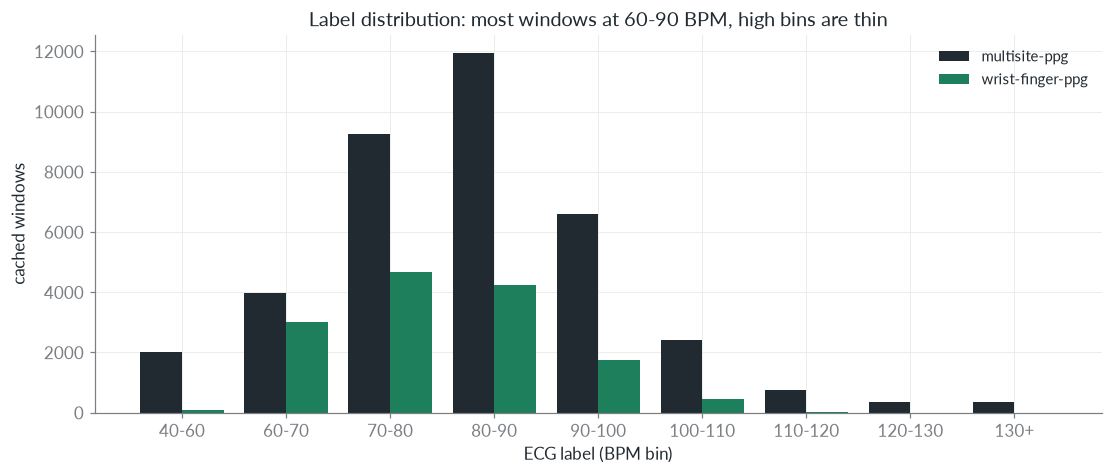

In [5]:
fig, ax = plt.subplots(figsize=figsize(1))
counts = pd.crosstab(L["bin"], L["dataset"])
x = np.arange(len(counts))
for i, d in enumerate(DATASETS):
    ax.bar(x + (i - 0.5) * 0.4, counts[d], 0.4, label=d, color=COLORS[d])
ax.set_xticks(x, counts.index)
ax.set_xlabel("ECG label (BPM bin)")
ax.set_ylabel("cached windows")
ax.set_title("Label distribution: most windows at 60-90 BPM, high bins are thin")
ax.legend()
save(fig, "data_labels")

## 2. Protocol

- 5 stratified subject groups per sub-dataset (`cache/folds.json`). Fold k: test = group k, val = group (k+1) % 5, train = rest. Every subject is in test exactly once.
- 3 seeds per config and fold (42, 1, 2): seed changes init, shuffle and augmentation only.
- **Decision** (`decide`): on **val** windows only. Per subject: median over seeds of the subject MAE. Key = mean over subjects of the gap to the best config, then mean over the two sub-datasets (paired). SE = subject bootstrap. Tie set = configs within 1 SE of the best; the winner is the tie-set config with the lowest bin-balanced val MAE (mean over BPM bins).
- **Global** decision pools the val sets of all 5 folds. **LTGO** check (leave-test-group-out): for test group k, decide without the fold whose val is group k, so the decision never saw those subjects.
- Greedy stages: A picks the loss (L*), B adds bootstrap + LDS to L*, C swaps the head to dist; final = better of B and C winner. Test numbers (`oof`) are reported after the choice, they never enter it.

## 3. Stage A: which loss?

Huber δ10, MAE, MSE; reg head, no bootstrap, LDS off.

In [6]:
def decisions(cands):
    out = {"global": decide(W, range(5), candidates=cands)}
    for k in range(5):
        out[f"k{k}"] = decide(W, ltgo_folds(k), candidates=cands)
    return out


def verdict(dec):
    return pd.DataFrame({name: {"winner": d.index[d["win"]][0], "tie set": ", ".join(d.index[d["tie"]])}
                         for name, d in dec.items()}).T


decA = decisions(STAGES["A"])
winA = decA["global"].index[decA["global"]["win"]][0]
gA = decA["global"]
put("stage_a", winner=winA, ltgo_agree=int(sum(d.index[d["win"]][0] == winA for k, d in decA.items() if k != "global")),
    **{f"key_{c}": gA.loc[c, "key"] for c in gA.index}, **{f"se_{c}": gA.loc[c, "se"] for c in gA.index},
    **{f"binbal_{c}": gA.loc[c, "bin_bal"] for c in gA.index})
display(gA[["key", "se", "tie", "bin_bal", "win"]].round(3))
verdict(decA)

,key,se,tie,bin_bal,win
config,,,,,
huber10,0.081,0.069,False,16.297,False
mae,0.123,0.084,False,16.843,False
mse,0.000,0.000,True,15.774,True


,winner,tie set
global,mse,mse
k0,mse,"huber10, mse"
k1,mse,mse
k2,mse,mse
k3,mse,"huber10, mse"
k4,mse,"huber10, mae, mse"


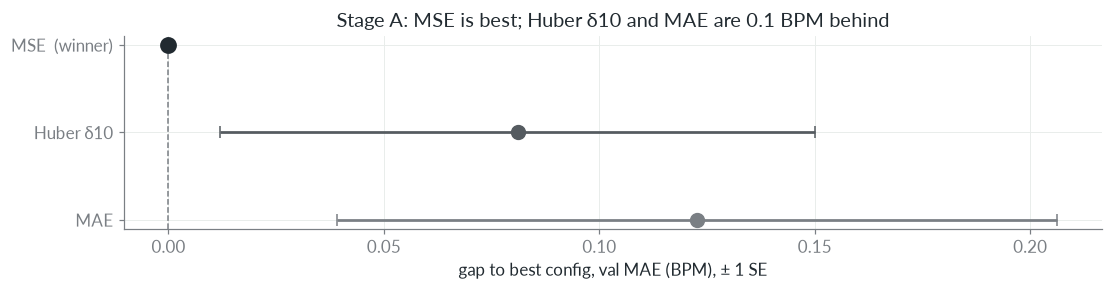

In [7]:
def plot_keys(ax, d, title):
    d = d.sort_values("key")
    y = np.arange(len(d))[::-1]
    for yi, (c, r) in zip(y, d.iterrows()):
        ax.errorbar(r["key"], yi, xerr=r["se"], fmt=MARKERS[lds_of(c)], ms=9, color=COLORS[c], capsize=4,
                    mec=COLORS["truth"] if r["win"] else COLORS[c], mew=2 if r["win"] else 1)
    ax.axvline(0, color=COLORS["ideal"], lw=STYLE["lw_thin"], ls="--")
    ax.set_yticks(y, [LABELS[c] + ("  (winner)" if d.loc[c, "win"] else "") for c in d.index])
    ax.set_xlabel("gap to best config, val MAE (BPM), ± 1 SE")
    ax.set_title(title)


fig, ax = plt.subplots(figsize=figsize(0.6))
plot_keys(ax, gA, "Stage A: MSE is best; Huber δ10 and MAE are 0.1 BPM behind")
save(fig, "stage_a_keys")

fold,0,1,2,3,4
config,,,,,
huber10,4.20,4.38,4.30,5.01,4.62
mae,4.25,4.49,4.30,5.25,4.47
mse,4.17,4.52,4.14,4.75,4.47


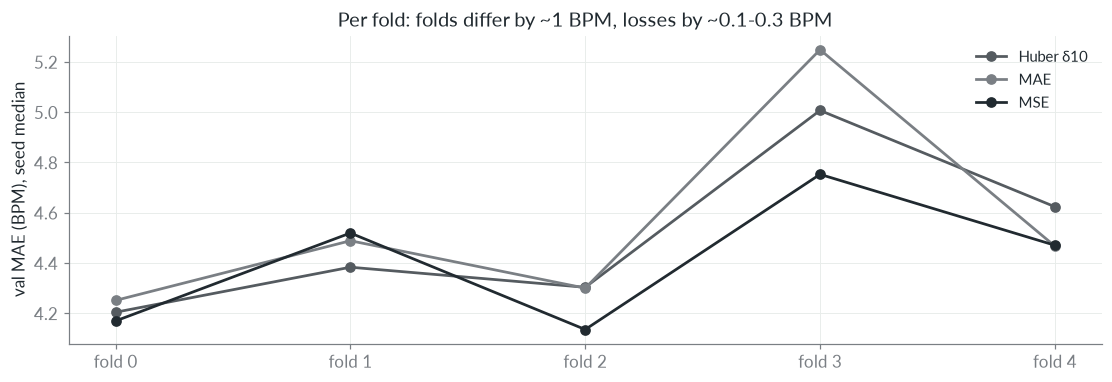

In [8]:
# per fold: seed-median val subject-macro MAE per config, to show how much folds differ vs configs
def fold_macro(cfgs, split="val"):
    v = W[(W["split"] == split) & W["config"].isin(cfgs)]
    s = subject_mae(v, by=("config", "fold", "seed"))
    return (s.groupby(["config", "fold", "seed"])[["dataset", "mae"]].apply(macro)
             .groupby(["config", "fold"]).median().unstack("fold"))


fmA = fold_macro(STAGES["A"])
fig, ax = plt.subplots(figsize=figsize(0.8))
for c in STAGES["A"]:
    ax.plot(range(5), fmA.loc[c], marker="o", color=COLORS[c], label=LABELS[c])
ax.set_xticks(range(5), [f"fold {k}" for k in range(5)])
ax.set_ylabel("val MAE (BPM), seed median")
ax.set_title("Per fold: folds differ by ~1 BPM, losses by ~0.1-0.3 BPM")
ax.legend()
save(fig, "stage_a_folds")
fmA.round(2)

## 4. The problem: pull to the middle

From the Stage A winner (MSE, reg head), test windows of all folds and seeds (each subject appears 3 times, once per seed). A regressor trained on a label distribution peaked at 60-90 BPM shrinks extreme labels toward the middle: high labels get under-predicted, low labels over-predicted. Measures: bias per BPM bin (mean of pred - truth), OLS slope of pred on truth (1 = no shrinkage), MAE in the 120+ bins.

In [9]:
def problem_stats(cfg, split="test"):
    t = W[(W["config"] == cfg) & (W["split"] == split)]
    g = t.assign(bias=t["pred"] - t["truth"]).groupby("bin", observed=False)
    per_bin = pd.DataFrame({"n": g.size(), "bias": g["bias"].mean(), "mae": g["err"].mean()})
    slope, icpt = np.polyfit(t["truth"], t["pred"], 1)
    return per_bin, slope, icpt


pbA, slopeA, icptA = problem_stats(winA)
hi = W[(W["config"] == winA) & (W["split"] == "test") & (W["truth"] >= 120)]
put("problem", slope=slopeA, intercept=icptA, mae_120plus=hi["err"].mean(), bias_120plus=(hi["pred"] - hi["truth"]).mean(),
    n_120plus=len(hi), mae_70_80=pbA.loc["70-80", "mae"], bias_40_60=pbA.loc["40-60", "bias"])
print(f"slope {slopeA:.3f}, intercept {icptA:.1f}; 120+ BPM: MAE {hi['err'].mean():.1f}, bias {(hi['pred'] - hi['truth']).mean():+.1f}, n={len(hi)}")
pbA.round(2)

slope 0.463, intercept 43.7; 120+ BPM: MAE 38.7, bias -38.7, n=2121


,n,bias,mae
bin,,,
40-60,6288,16.21,16.61
60-70,20931,5.84,6.58
70-80,41808,2.29,3.76
80-90,48513,-0.37,3.04
90-100,25053,-5.00,5.91
100-110,8568,-11.59,11.98
110-120,2310,-22.16,22.28
120-130,1101,-31.12,31.13
130+,1020,-46.82,46.82


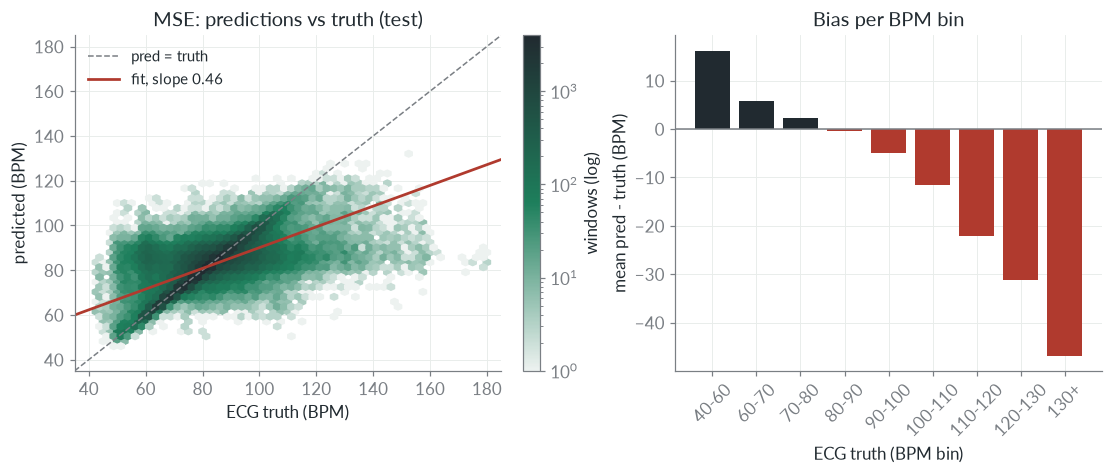

In [10]:
t = W[(W["config"] == winA) & (W["split"] == "test")]
fig, axes = plt.subplots(1, 2, figsize=figsize(1))
ax = axes[0]
hb = ax.hexbin(t["truth"], t["pred"], gridsize=60, bins="log", cmap=DENSITY_CMAP, mincnt=1, extent=(35, 185, 35, 185))
lim = np.array([35, 185])
ax.plot(lim, lim, color=COLORS["ideal"], ls="--", lw=STYLE["lw_thin"], label="pred = truth")
ax.plot(lim, slopeA * lim + icptA, color=COLORS["bad"], label=f"fit, slope {slopeA:.2f}")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("ECG truth (BPM)"); ax.set_ylabel("predicted (BPM)")
ax.set_title("MSE: predictions vs truth (test)")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="windows (log)")
ax = axes[1]
x = np.arange(len(pbA))
ax.bar(x, pbA["bias"], color=[COLORS["bad"] if b < 0 else COLORS["truth"] for b in pbA["bias"]])
ax.axhline(0, color=COLORS["muted"], lw=STYLE["lw_thin"])
ax.set_xticks(x, pbA.index, rotation=45)
ax.set_xlabel("ECG truth (BPM bin)"); ax.set_ylabel("mean pred - truth (BPM)")
ax.set_title("Bias per BPM bin")
save(fig, "problem")

## 5. Stage B: fix the tails with data (bootstrap) and weights (LDS)

L* = MSE plus time-warped bootstrap windows in the low and high bins (`HL`), and label-distribution-smoothing loss weights with power p ∈ {0, 0.5, 1} (p = 0 = off). Decided among the 3 B configs only.

In [11]:
decB = decisions(STAGES["B"])
winB = decB["global"].index[decB["global"]["win"]][0]
gB = decB["global"]
put("stage_b", winner=winB, ltgo_agree=int(sum(d.index[d["win"]][0] == winB for k, d in decB.items() if k != "global")),
    **{f"key_{c}": gB.loc[c, "key"] for c in gB.index}, **{f"se_{c}": gB.loc[c, "se"] for c in gB.index})
display(gB[["key", "se", "tie", "bin_bal", "win"]].round(3))
verdict(decB)

,key,se,tie,bin_bal,win
config,,,,,
mse_bootHL,0.000,0.000,True,15.535,True
mse_bootHL_lds0.5,0.849,0.111,False,14.511,False
mse_bootHL_lds1,2.254,0.230,False,13.813,False


,winner,tie set
global,mse_bootHL,mse_bootHL
k0,mse_bootHL,mse_bootHL
k1,mse_bootHL,mse_bootHL
k2,mse_bootHL,mse_bootHL
k3,mse_bootHL,mse_bootHL
k4,mse_bootHL,mse_bootHL


bin,40-60,60-70,70-80,80-90,90-100,100-110,110-120,120-130,130+
config,,,,,,,,,
mse,13.89,5.51,3.69,3.06,5.49,11.68,21.02,30.35,46.83
mse_bootHL,13.41,5.81,4.01,3.67,6.93,12.84,21.73,29.80,42.24
mse_bootHL_lds0.5,14.90,6.93,5.62,5.39,6.80,10.88,17.89,24.65,37.13
mse_bootHL_lds1,16.61,8.63,8.41,8.10,7.46,9.02,13.00,20.01,30.84


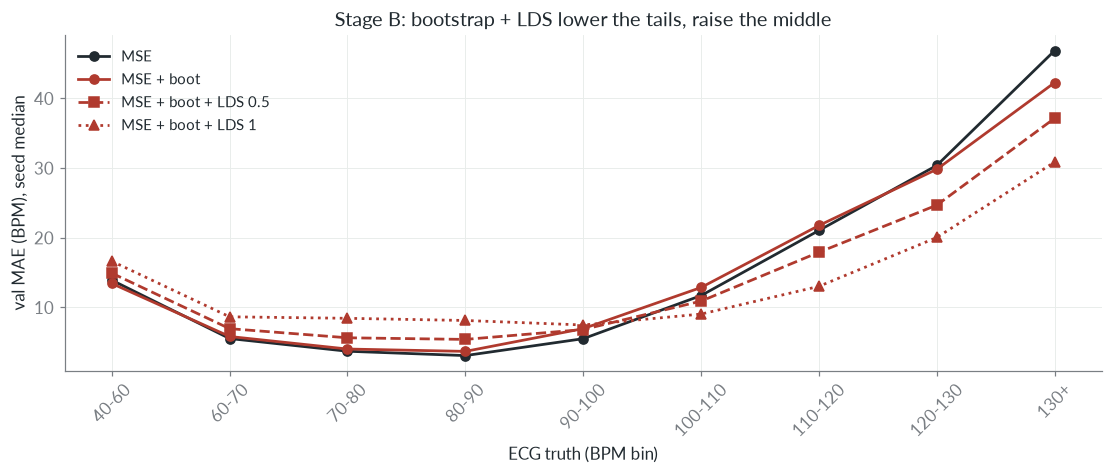

In [12]:
def per_bin_mae(cfgs, split="val"):
    v = W[(W["split"] == split) & W["config"].isin(cfgs)]
    # seed median of the window-pooled per-bin MAE
    return (v.groupby(["config", "seed", "bin"], observed=False)["err"].mean()
             .groupby(["config", "bin"], observed=False).median().unstack("bin"))


def plot_bins(ax, cfgs, split, title):
    m = per_bin_mae(cfgs, split)
    x = np.arange(len(BIN_LABELS))
    for c in cfgs:
        ax.plot(x, m.loc[c, BIN_LABELS], marker=MARKERS[lds_of(c)], ls=LINESTYLES[lds_of(c)], color=COLORS[c], label=LABELS[c])
    ax.set_xticks(x, BIN_LABELS, rotation=45)
    ax.set_xlabel("ECG truth (BPM bin)"); ax.set_ylabel(f"{split} MAE (BPM), seed median")
    ax.set_title(title)
    ax.legend()
    return m


fig, ax = plt.subplots(figsize=figsize(1))
mB = plot_bins(ax, ["mse", *STAGES["B"]], "val", "Stage B: bootstrap + LDS lower the tails, raise the middle")
save(fig, "stage_b_bins")
mB.round(2)

## 6. Stage C: distribution head

Same bootstrap and LDS grid with the `dist` head: 191 1-BPM bins (30-220), Gaussian-target cross-entropy, BPM = expectation of the softmax. Decided among the 3 C configs, then final = better of the B and C winner.

In [13]:
decC = decisions(STAGES["C"])
winC = decC["global"].index[decC["global"]["win"]][0]
decF = decisions([winB, winC])
final = decF["global"].index[decF["global"]["win"]][0]
gC, gF = decC["global"], decF["global"]
gAll = decide(W, range(5))  # all 9 together, for the overview figure
put("stage_c", winner=winC, ltgo_agree=int(sum(d.index[d["win"]][0] == winC for k, d in decC.items() if k != "global")),
    **{f"key_{c}": gC.loc[c, "key"] for c in gC.index}, **{f"se_{c}": gC.loc[c, "se"] for c in gC.index})
put("final", config=final, ltgo_agree=int(sum(d.index[d["win"]][0] == final for k, d in decF.items() if k != "global")),
    gap_B_vs_C=gF.loc[winB, "key"] if final == winC else gF.loc[winC, "key"],
    se_B_vs_C=gF.loc[winB, "se"] if final == winC else gF.loc[winC, "se"],
    **{f"all_key_{c}": gAll.loc[c, "key"] for c in gAll.index}, **{f"all_se_{c}": gAll.loc[c, "se"] for c in gAll.index},
    **{f"all_binbal_{c}": gAll.loc[c, "bin_bal"] for c in gAll.index})
display(gC[["key", "se", "tie", "bin_bal", "win"]].round(3))
display(verdict(decC))
display(verdict(decF))
gAll[["key", "se", "bin_bal", "bin_bal_sd"]].sort_values("key").round(3)

,key,se,tie,bin_bal,win
config,,,,,
dist_bootHL,0.000,0.000,True,14.615,True
dist_bootHL_lds0.5,0.465,0.079,False,13.427,False
dist_bootHL_lds1,2.286,0.355,False,12.700,False


,winner,tie set
global,dist_bootHL,dist_bootHL
k0,dist_bootHL,dist_bootHL
k1,dist_bootHL,dist_bootHL
k2,dist_bootHL,dist_bootHL
k3,dist_bootHL,dist_bootHL
k4,dist_bootHL,dist_bootHL


,winner,tie set
global,dist_bootHL,dist_bootHL
k0,dist_bootHL,dist_bootHL
k1,dist_bootHL,dist_bootHL
k2,dist_bootHL,dist_bootHL
k3,dist_bootHL,dist_bootHL
k4,dist_bootHL,dist_bootHL


,key,se,bin_bal,bin_bal_sd
config,,,,
dist_bootHL,0.000,0.000,14.615,0.126
mse,0.238,0.104,15.774,0.344
huber10,0.319,0.097,16.297,0.305
mae,0.361,0.103,16.843,0.208
dist_bootHL_lds0.5,0.465,0.079,13.427,0.102
mse_bootHL,0.662,0.076,15.535,0.088
mse_bootHL_lds0.5,1.511,0.122,14.511,0.309
dist_bootHL_lds1,2.286,0.355,12.700,0.134
mse_bootHL_lds1,2.916,0.218,13.813,0.415


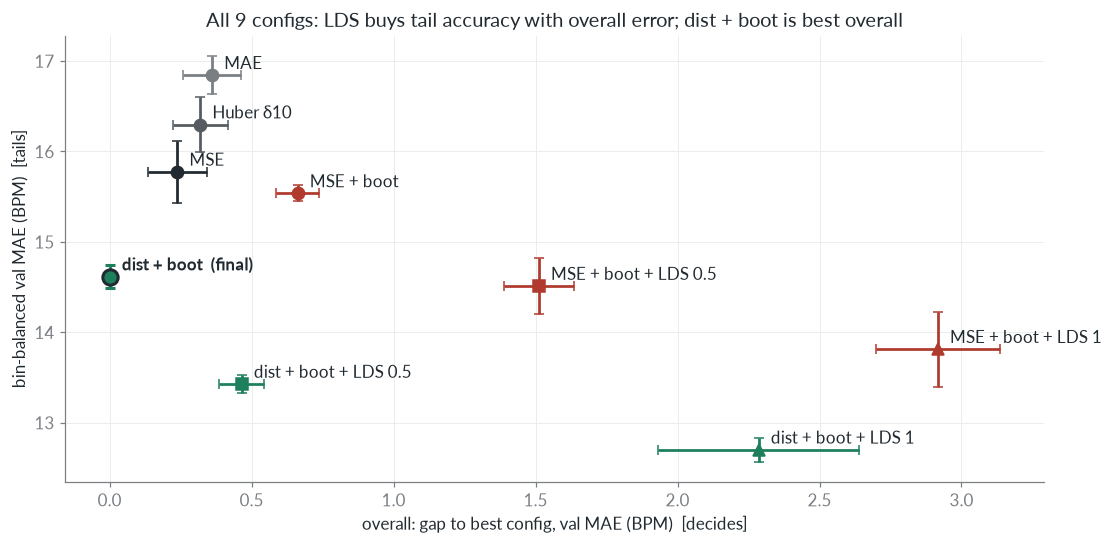

In [14]:
fig, ax = plt.subplots(figsize=figsize(1.15))
for c, r in gAll.iterrows():
    win = c == final
    ax.errorbar(r["key"], r["bin_bal"], xerr=r["se"], yerr=r["bin_bal_sd"], fmt=MARKERS[lds_of(c)], ms=10 if win else 8,
                color=COLORS[c], capsize=3, mec=COLORS["truth"] if win else COLORS[c], mew=2 if win else 1)
    ax.annotate(LABELS[c] + ("  (final)" if win else ""), (r["key"], r["bin_bal"]), xytext=(8, 4),
                textcoords="offset points", color=COLORS["text"], fontweight="bold" if win else "normal")
ax.set_xlabel("overall: gap to best config, val MAE (BPM)  [decides]")
ax.set_ylabel("bin-balanced val MAE (BPM)  [tails]")
ax.set_title("All 9 configs: LDS buys tail accuracy with overall error; dist + boot is best overall")
save(fig, "tradeoff")

mse        mse_bootHL        dist_bootHL       
          bias    mae       bias    mae        bias    mae
bin                                                       
40-60    16.21  16.61      13.56  14.34       12.81  13.48
60-70     5.84   6.58       5.49   6.52        5.30   5.93
70-80     2.29   3.76       2.14   4.10        2.77   3.85
80-90    -0.37   3.04      -0.83   3.76        0.39   3.04
90-100   -5.00   5.91      -5.55   7.13       -4.04   5.86
100-110 -11.59  11.98     -12.05  13.12      -10.59  12.06
110-120 -22.16  22.28     -21.68  22.85      -19.92  21.61
120-130 -31.12  31.13     -27.78  30.06      -25.41  29.34
130+    -46.82  46.82     -40.87  41.23      -39.84  40.75

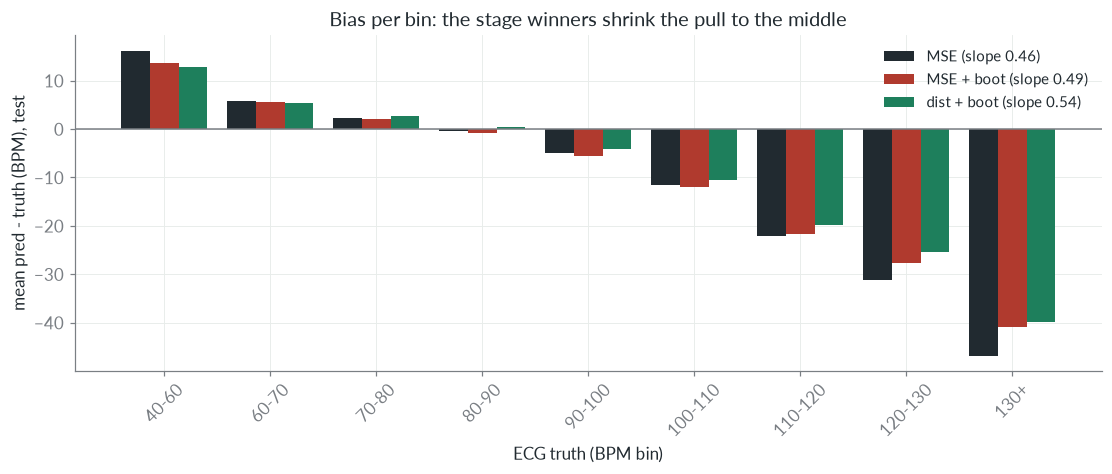

In [15]:
fig, ax = plt.subplots(figsize=figsize(1))
pb = {c: problem_stats(c)[0] for c in ["mse", winB, winC]}
x = np.arange(len(BIN_LABELS))
for i, c in enumerate(pb):
    ax.bar(x + (i - 1) * 0.27, pb[c]["bias"], 0.27, color=COLORS[c], label=f"{LABELS[c]} (slope {problem_stats(c)[1]:.2f})")
ax.axhline(0, color=COLORS["muted"], lw=STYLE["lw_thin"])
ax.set_xticks(x, BIN_LABELS, rotation=45)
ax.set_xlabel("ECG truth (BPM bin)"); ax.set_ylabel("mean pred - truth (BPM), test")
ax.set_title("Bias per bin: the stage winners shrink the pull to the middle")
ax.legend()
save(fig, "bias_winners")
put("problem", **{f"slope_{c}": problem_stats(c)[1] for c in pb},
    **{f"mae_120plus_{c}": W[(W["config"] == c) & (W["split"] == "test") & (W["truth"] >= 120)]["err"].mean() for c in pb})
pd.concat({c: v[["bias", "mae"]] for c, v in pb.items()}, axis=1).round(2)

## 7. Test results (out-of-fold, after the choice)

Each seed pools its 5 test folds = every subject once; subject-macro balanced MAE, mean ± std over the 3 seeds. 95 % CI of the difference to MSE by subject bootstrap; Wilcoxon signed-rank per sub-dataset on paired per-subject MAE, Holm-adjusted over configs (all from `cache/results/summary.csv`, `bpm.aggregate.vs_baseline`).

In [16]:
S = pd.read_csv(RESULTS / "summary.csv", index_col="config").loc[CONFIGS]
cols = ["oof_mean", "oof_std", "oof_ci_lo", "oof_ci_hi", "diff_ci_lo", "diff_ci_hi",
        "p_multisite-ppg_holm", "p_wrist-finger-ppg_holm"]
T = S[cols].copy()
# cross-check: recompute oof_mean from W
chk = (subject_mae(W[W["split"] == "test"], by=("config", "seed")).groupby(["config", "seed"])[["dataset", "mae"]]
       .apply(macro).groupby("config").mean())
assert np.allclose(chk.loc[CONFIGS], T["oof_mean"]), (chk, T["oof_mean"])
put("test", **{f"oof_{c}": T.loc[c, "oof_mean"] for c in CONFIGS}, **{f"oof_std_{c}": T.loc[c, "oof_std"] for c in CONFIGS},
    **{f"diff_lo_{c}": T.loc[c, "diff_ci_lo"] for c in CONFIGS}, **{f"diff_hi_{c}": T.loc[c, "diff_ci_hi"] for c in CONFIGS},
    **{f"p_ms_{c}": T.loc[c, "p_multisite-ppg_holm"] for c in CONFIGS}, **{f"p_wf_{c}": T.loc[c, "p_wrist-finger-ppg_holm"] for c in CONFIGS})
T.round(3)

,oof_mean,oof_std,oof_ci_lo,oof_ci_hi,diff_ci_lo,diff_ci_hi,p_multisite-ppg_holm,p_wrist-finger-ppg_holm
config,,,,,,,,
huber10,4.721,0.063,4.061,5.450,-0.055,0.214,0.674,0.077
mae,4.872,0.040,4.207,5.594,0.079,0.381,0.069,0.000
mse,4.640,0.043,3.956,5.416,0.000,0.000,NaN,NaN
mse_bootHL,4.978,0.093,4.367,5.647,0.173,0.487,0.014,0.021
mse_bootHL_lds0.5,5.971,0.148,5.341,6.714,1.089,1.574,0.000,0.000
mse_bootHL_lds1,7.380,0.209,6.616,8.176,2.240,3.209,0.000,0.000
dist_bootHL,4.375,0.069,3.811,4.990,-0.466,-0.060,0.307,0.001
dist_bootHL_lds0.5,4.836,0.099,4.257,5.470,-0.138,0.536,0.228,0.000
dist_bootHL_lds1,6.634,0.223,5.894,7.428,1.359,2.670,0.000,0.077


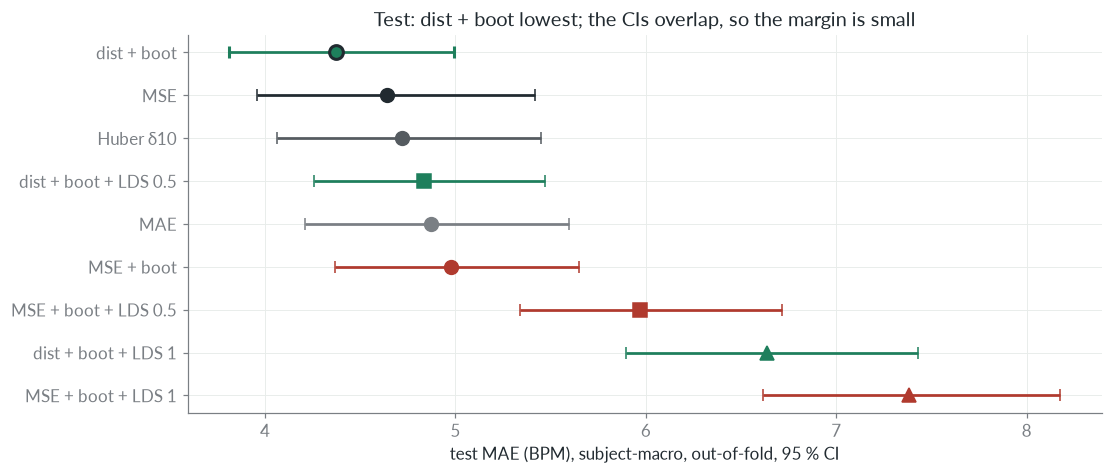

In [17]:
fig, ax = plt.subplots(figsize=figsize(1))
d = T.sort_values("oof_mean")
y = np.arange(len(d))[::-1]
for yi, (c, r) in zip(y, d.iterrows()):
    ax.errorbar(r["oof_mean"], yi, xerr=[[r["oof_mean"] - r["oof_ci_lo"]], [r["oof_ci_hi"] - r["oof_mean"]]],
                fmt=MARKERS[lds_of(c)], ms=9, color=COLORS[c], capsize=4,
                mec=COLORS["truth"] if c == final else COLORS[c], mew=2 if c == final else 1)
ax.set_yticks(y, [LABELS[c] for c in d.index])
ax.set_xlabel("test MAE (BPM), subject-macro, out-of-fold, 95 % CI")
ax.set_title("Test: dist + boot lowest; the CIs overlap, so the margin is small")
save(fig, "test_oof")

## Summary values (what the deck cites)

In [18]:
print(json.dumps({k: VALUES[k] for k in ["data", "stage_a", "problem", "stage_b", "stage_c", "final"]}, indent=1, default=float)[:4000])

{
 "data": {
  "subjects": 47,
  "windows": 51864,
  "subjects_multisite-ppg": 20,
  "subjects_wrist-finger-ppg": 27,
  "windows_multisite-ppg": 37668,
  "windows_wrist-finger-ppg": 14196,
  "share_60_90": 71.50239086842511,
  "share_110plus": 2.847832793459818
 },
 "stage_a": {
  "winner": "mse",
  "ltgo_agree": 5,
  "key_huber10": 0.0810318792818847,
  "key_mae": 0.12269859095232426,
  "key_mse": 0.0,
  "se_huber10": 0.0689853349605428,
  "se_mae": 0.08361622361234126,
  "se_mse": 0.0,
  "binbal_huber10": 16.29667904376361,
  "binbal_mae": 16.842714470243482,
  "binbal_mse": 15.774019496923538
 },
 "problem": {
  "slope": 0.4634508876387053,
  "intercept": 43.739317756252966,
  "mae_120plus": 38.67487277112328,
  "bias_120plus": -38.669490152347315,
  "n_120plus": 2121,
  "mae_70_80": 3.7637149230119054,
  "bias_40_60": 16.20672445200175,
  "slope_mse": 0.4634508876387053,
  "slope_mse_bootHL": 0.4940037621489753,
  "slope_dist_bootHL": 0.5366778137797608,
  "mae_120plus_mse": 38.674